# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

- Implement multiple hill climbing search variants to solve the n-Queens problem.
- Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
- Compare algorithm performance using runtime, solution quality, and success rate metrics.
- Analyze and visualize algorithm performance across different problem sizes.
- Graduate Students: Design and test alternative local move operators to improve search efficiency.


## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.


In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

- **Goal:** Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

- **State space:** An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

- **Objective function:** The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
  The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

- **Local improvement move:** Move one queen to a different row in its column.

- **Termination:** For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.


## Helper functions


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board


Board with 4 conflicts.


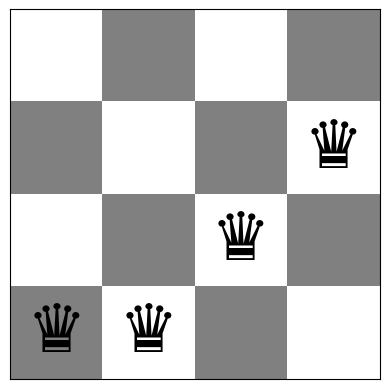

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:


Board with 0 conflicts.


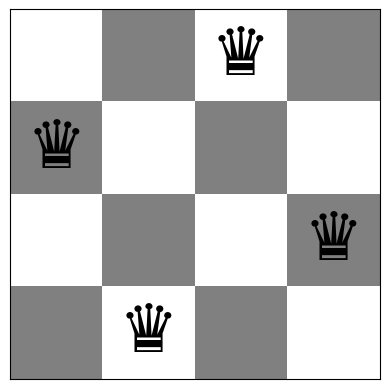

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
   - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
   - Do not show debugging output or include an excessive amount of output.
   - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.


### Design notes

A local move changes the row of exactly one queen while keeping its column fixed. The helper below validates a board and returns a consistent result dictionary. `steepest_ascent_hill_climbing()` evaluates all `n(n-1)` local moves at each step and deterministically picks the first best improving move. It stops at a local optimum (or a valid solution), so its `evaluations` metric makes its computational cost explicit.

**How to call:** `steepest_ascent_hill_climbing(random_board(8))`. The optional `max_iterations` is a safety limit.

**Reproducible examples:** with the included seeds, the n=4 example goes from `f=2` to `f=1` in 1 accepted step (25 evaluations), and the n=8 example goes from `f=7` to `f=1` in 3 accepted steps (225 evaluations). Both runs stop at a local optimum, illustrating why a single greedy run is not guaranteed to solve n-Queens.

```python
def _validate_board(board):
    state = np.asarray(board, dtype=int).copy()
    n = len(state)
    if state.ndim != 1 or n < 1 or np.any(state < 0) or np.any(state >= n):
        raise ValueError("board must be a one-dimensional vector with values in [0, n)")
    return state


def _search_result(state, objective, history, iterations, evaluations, stopped_reason):
    """Return the shared result format used by all n-Queens searches."""
    return {
        "solution": state.copy(),
        "objective": int(objective),
        "history": history,
        "iterations": iterations,
        "evaluations": evaluations,
        "stopped_reason": stopped_reason,
    }


def steepest_ascent_hill_climbing(board, max_iterations=10_000):
    """Minimize conflicts by evaluating every one-queen local move."""
    state = _validate_board(board)
    n = len(state)
    current_objective = conflicts(state)
    history, evaluations, iterations = [int(current_objective)], 1, 0

    while iterations < max_iterations and current_objective > 0:
        best_state, best_objective = None, current_objective
        for column in range(n):
            old_row = state[column]
            for row in range(n):
                if row == old_row:
                    continue
                candidate = state.copy()
                candidate[column] = row
                candidate_objective = conflicts(candidate)
                evaluations += 1
                if candidate_objective < best_objective:
                    best_state, best_objective = candidate, candidate_objective

        if best_state is None:
            return _search_result(state, current_objective, history, iterations, evaluations, "local optimum")

        state, current_objective = best_state, best_objective
        iterations += 1
        history.append(int(current_objective))

    reason = "solution found" if current_objective == 0 else "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


# Reproducible examples: n=4 and n=8
for n, seed in [(4, 2026), (8, 2027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = steepest_ascent_hill_climbing(initial)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"steps={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")
```


In [5]:
def _validate_board(board):
    state = np.asarray(board, dtype=int).copy()
    n = len(state)
    if state.ndim != 1 or n < 1 or np.any(state < 0) or np.any(state >= n):
        raise ValueError("board must be a one-dimensional vector with values in [0, n)")
    return state


def _search_result(state, objective, history, iterations, evaluations, stopped_reason):
    return {"solution": state.copy(), "objective": int(objective),
            "history": history, "iterations": iterations,
            "evaluations": evaluations, "stopped_reason": stopped_reason}


def steepest_ascent_hill_climbing(board, max_iterations=10_000):
    """Minimize conflicts by evaluating every one-queen local move."""
    state = _validate_board(board)
    n, current_objective = len(state), conflicts(state)
    history, evaluations, iterations = [int(current_objective)], 1, 0

    while iterations < max_iterations and current_objective > 0:
        best_state, best_objective = None, current_objective
        for column in range(n):
            for row in range(n):
                if row == state[column]:
                    continue
                candidate = state.copy()
                candidate[column] = row
                candidate_objective = conflicts(candidate)
                evaluations += 1
                if candidate_objective < best_objective:
                    best_state, best_objective = candidate, candidate_objective
        if best_state is None:
            return _search_result(state, current_objective, history, iterations, evaluations, "local optimum")
        state, current_objective = best_state, best_objective
        iterations += 1
        history.append(int(current_objective))

    reason = "solution found" if current_objective == 0 else "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


for n, seed in [(4, 2026), (8, 2027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = steepest_ascent_hill_climbing(initial)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"steps={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")

n=4 | initial f=2 | final f=1 | steps=1 | evaluations=25 | local optimum
n=8 | initial f=7 | final f=1 | steps=3 | evaluations=225 | local optimum


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.


### Design notes

This version has the same complete neighbourhood scan as Steepest-ascent, but it randomly selects one candidate from all strictly improving moves. It therefore explores different improving trajectories, while retaining the high evaluation cost of checking every local move.

**How to call:** `inefficient_stochastic_hill_climbing(random_board(8), seed=42)`. A seed makes the random choices repeatable.

**Reproducible examples:** with the included seeds, n=4 goes from `f=4` to `f=2` after 2 steps and 37 evaluations; n=8 goes from `f=7` to a solution (`f=0`) after 5 steps and 281 evaluations. Results differ by seed because the improving move is selected randomly.

```python
def inefficient_stochastic_hill_climbing(board, max_iterations=10_000, seed=None):
    """Choose uniformly from all improving one-queen local moves."""
    state = _validate_board(board)
    n = len(state)
    rng = np.random.default_rng(seed)
    current_objective = conflicts(state)
    history, evaluations, iterations = [int(current_objective)], 1, 0

    while iterations < max_iterations and current_objective > 0:
        improving_moves = []
        for column in range(n):
            old_row = state[column]
            for row in range(n):
                if row == old_row:
                    continue
                candidate = state.copy()
                candidate[column] = row
                candidate_objective = conflicts(candidate)
                evaluations += 1
                if candidate_objective < current_objective:
                    improving_moves.append((candidate, candidate_objective))

        if not improving_moves:
            return _search_result(state, current_objective, history, iterations, evaluations, "local optimum")

        selected = int(rng.integers(len(improving_moves)))
        state, current_objective = improving_moves[selected]
        iterations += 1
        history.append(int(current_objective))

    reason = "solution found" if current_objective == 0 else "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


for n, seed in [(4, 3026), (8, 3027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = inefficient_stochastic_hill_climbing(initial, seed=seed)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"steps={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")
```


In [6]:
def inefficient_stochastic_hill_climbing(board, max_iterations=10_000, seed=None):
    """Choose uniformly from all improving one-queen local moves."""
    state = _validate_board(board)
    n, rng = len(state), np.random.default_rng(seed)
    current_objective = conflicts(state)
    history, evaluations, iterations = [int(current_objective)], 1, 0

    while iterations < max_iterations and current_objective > 0:
        improving_moves = []
        for column in range(n):
            for row in range(n):
                if row == state[column]:
                    continue
                candidate = state.copy()
                candidate[column] = row
                candidate_objective = conflicts(candidate)
                evaluations += 1
                if candidate_objective < current_objective:
                    improving_moves.append((candidate, candidate_objective))
        if not improving_moves:
            return _search_result(state, current_objective, history, iterations, evaluations, "local optimum")
        state, current_objective = improving_moves[int(rng.integers(len(improving_moves)))]
        iterations += 1
        history.append(int(current_objective))

    reason = "solution found" if current_objective == 0 else "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


for n, seed in [(4, 3026), (8, 3027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = inefficient_stochastic_hill_climbing(initial, seed=seed)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"steps={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")

n=4 | initial f=4 | final f=2 | steps=2 | evaluations=37 | local optimum
n=8 | initial f=7 | final f=0 | steps=5 | evaluations=281 | solution found


**Important note:** This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.


## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

**Notes:**

- Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.


### Design notes

First-choice Hill Climbing evaluates exactly one randomly generated local neighbour per trial and accepts it only if it improves the objective. It is much cheaper per trial than the two algorithms above. Since it does not inspect the complete neighbourhood, it stops after a configurable number of consecutive failed trials rather than claiming to prove a local optimum. The default is `3 × n × (n-1)`, i.e. three times the number of possible one-queen moves, which reduces the chance of stopping after missing a rare improvement.

**How to call:** `efficient_stochastic_hill_climbing(random_board(8), seed=42)`. Optionally set `max_non_improving_trials` and `max_iterations`.

**Reproducible examples:** with the included seeds, n=4 improves from `f=3` to `f=1` using 42 evaluations, while n=8 improves from `f=6` to `f=2` using 197 evaluations. Both stop at the failed-trial limit; this is expected because this method samples rather than exhaustively checks the neighbourhood.

```python
def efficient_stochastic_hill_climbing(
    board, max_iterations=10_000, max_non_improving_trials=None, seed=None
):
    """First-choice HC: sample one local move and accept it only if it improves."""
    state = _validate_board(board)
    n = len(state)
    if max_non_improving_trials is None:
        max_non_improving_trials = 3 * n * (n - 1)
    if max_non_improving_trials < 1:
        raise ValueError("max_non_improving_trials must be at least 1")

    rng = np.random.default_rng(seed)
    current_objective = conflicts(state)
    history, evaluations, iterations, failed_trials = [int(current_objective)], 1, 0, 0

    while (iterations < max_iterations and current_objective > 0
           and failed_trials < max_non_improving_trials):
        column = int(rng.integers(n))
        old_row = state[column]
        row = int(rng.integers(n - 1))
        if row >= old_row:
            row += 1

        candidate = state.copy()
        candidate[column] = row
        candidate_objective = conflicts(candidate)
        evaluations += 1
        iterations += 1

        if candidate_objective < current_objective:
            state, current_objective, failed_trials = candidate, candidate_objective, 0
        else:
            failed_trials += 1
        history.append(int(current_objective))

    if current_objective == 0:
        reason = "solution found"
    elif failed_trials >= max_non_improving_trials:
        reason = "no improvement trial limit"
    else:
        reason = "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


for n, seed in [(4, 4026), (8, 4027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = efficient_stochastic_hill_climbing(initial, seed=seed)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"trials={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")
```


In [7]:
def efficient_stochastic_hill_climbing(
    board, max_iterations=10_000, max_non_improving_trials=None, seed=None
):
    """First-choice HC: sample one move and accept it only if it improves."""
    state = _validate_board(board)
    n = len(state)
    if max_non_improving_trials is None:
        max_non_improving_trials = 3 * n * (n - 1)
    if max_non_improving_trials < 1:
        raise ValueError("max_non_improving_trials must be at least 1")

    rng = np.random.default_rng(seed)
    current_objective = conflicts(state)
    history, evaluations, iterations, failed_trials = [int(current_objective)], 1, 0, 0

    while (iterations < max_iterations and current_objective > 0
           and failed_trials < max_non_improving_trials):
        column = int(rng.integers(n))
        old_row = state[column]
        row = int(rng.integers(n - 1))
        if row >= old_row:
            row += 1
        candidate = state.copy()
        candidate[column] = row
        candidate_objective = conflicts(candidate)
        evaluations += 1
        iterations += 1

        if candidate_objective < current_objective:
            state, current_objective, failed_trials = candidate, candidate_objective, 0
        else:
            failed_trials += 1
        history.append(int(current_objective))

    if current_objective == 0:
        reason = "solution found"
    elif failed_trials >= max_non_improving_trials:
        reason = "no improvement trial limit"
    else:
        reason = "iteration limit"
    return _search_result(state, current_objective, history, iterations, evaluations, reason)


for n, seed in [(4, 4026), (8, 4027)]:
    initial = np.random.default_rng(seed).integers(0, n, size=n)
    result = efficient_stochastic_hill_climbing(initial, seed=seed)
    print(f"n={n} | initial f={conflicts(initial)} | final f={result['objective']} | "
          f"trials={result['iterations']} | evaluations={result['evaluations']} | {result['stopped_reason']}")

n=4 | initial f=3 | final f=1 | trials=41 | evaluations=42 | no improvement trial limit
n=8 | initial f=6 | final f=2 | trials=196 | evaluations=197 | no improvement trial limit


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

### Design notes: Hill Climbing with Random Restarts

Hill climbing algorithms easily get trapped in local optima or plateaus. **Random Restart Hill Climbing** overcomes this limitation by restarting the search from a freshly generated random configuration whenever a local optimum or termination condition is reached, running up to a specified maximum number of restarts (default: 100).

**Algorithm Structure:**
1. Maintain `best_solution`, `best_objective` (initialized to $\infty$), cumulative `iterations`, and cumulative `evaluations`.
2. In each restart $r = 1, 2, \dots, \text{max\_restarts}$:
   - Generate a new uniform random board of size $n$.
   - Execute the chosen Hill Climbing variant (`steepest_ascent_hill_climbing`, `inefficient_stochastic_hill_climbing`, or `efficient_stochastic_hill_climbing`).
   - Accumulate evaluations and iterations into the global counters.
   - If the run finds a strictly better solution, update `best_solution` and `best_objective`.
   - If an optimal solution (`best_objective == 0`) is discovered, terminate immediately.
3. Return the result dictionary containing `solution`, `objective`, `history`, `iterations`, `evaluations`, `restarts`, `success`, and `stopped_reason`.

**Metrics Tracked:**
- `objective`: Final best number of conflicts found.
- `restarts`: Actual number of restarts executed before finding a solution or hitting the limit.
- `success`: Boolean indicating whether an optimal zero-conflict solution was achieved.
- `evaluations` & `iterations`: Total computational effort across all restarts.


In [8]:
def random_restart_hill_climbing(
    search_func,
    n,
    max_restarts=100,
    seed=None,
    **search_kwargs
):
    """Random Restart wrapper for any Hill Climbing search variant.
    
    Parameters:
        search_func: The base search function to run on each restart.
        n: Board size (number of queens).
        max_restarts: Maximum number of independent restarts (default: 100).
        seed: Random seed for reproducible board generation and search trials.
        **search_kwargs: Additional parameters forwarded to search_func.
        
    Returns:
        Dictionary adhering to the standard result API, augmented with
        'restarts' and 'success' flags.
    """
    rng = np.random.default_rng(seed)
    best_result = None
    best_objective = float('inf')
    total_evaluations = 0
    total_iterations = 0
    restarts_used = 0
    combined_history = []

    for r in range(max_restarts):
        restarts_used += 1
        init_board = rng.integers(0, n, size=n)
        
        # Pass an independent deterministic seed to the inner search if accepted
        kwargs = search_kwargs.copy()
        if 'seed' in search_func.__code__.co_varnames:
            kwargs['seed'] = int(rng.integers(0, 2**31 - 1))
            
        res = search_func(init_board, **kwargs)
        total_evaluations += res['evaluations']
        total_iterations += res['iterations']
        combined_history.extend(res['history'])
        
        if res['objective'] < best_objective:
            best_objective = res['objective']
            best_result = res
            
        if best_objective == 0:
            break
            
    reason = "solution found" if best_objective == 0 else "max restarts reached"
    return {
        "solution": best_result['solution'].copy(),
        "objective": int(best_objective),
        "history": combined_history,
        "iterations": total_iterations,
        "evaluations": total_evaluations,
        "restarts": restarts_used,
        "success": bool(best_objective == 0),
        "stopped_reason": reason,
    }


# ==============================================================================
# Demonstration of Random Restart on all three Hill Climbing variants (n=4 and n=8)
# ==============================================================================
hc_variants = [
    ("Steepest-Ascent HC", steepest_ascent_hill_climbing),
    ("Inefficient Stochastic HC", inefficient_stochastic_hill_climbing),
    ("Efficient Stochastic HC", efficient_stochastic_hill_climbing),
]

print("=== Task 4: Random Restart Hill Climbing Evaluation (max 100 restarts) ===")
print(f"{'Algorithm':<26} | {'n':<2} | {'Obj':<3} | {'Restarts':<8} | {'Success':<7} | {'Total Evals':<11} | {'Reason'}")
print("-" * 88)

for n_val, master_seed in [(4, 4004), (8, 4008)]:
    for name, fn in hc_variants:
        rr_res = random_restart_hill_climbing(fn, n_val, max_restarts=100, seed=master_seed)
        print(f"{name:<26} | {n_val:<2} | {rr_res['objective']:<3} | {rr_res['restarts']:<8} | "
              f"{str(rr_res['success']):<7} | {rr_res['evaluations']:<11} | {rr_res['stopped_reason']}")
    print("-" * 88)


=== Task 4: Random Restart Hill Climbing Evaluation (max 100 restarts) ===
Algorithm                  | n  | Obj | Restarts | Success | Total Evals | Reason
----------------------------------------------------------------------------------------
Steepest-Ascent HC         | 4  | 0   | 1        | True    | 13          | solution found
Inefficient Stochastic HC  | 4  | 0   | 1        | True    | 13          | solution found
Efficient Stochastic HC    | 4  | 0   | 1        | True    | 16          | solution found
----------------------------------------------------------------------------------------
Steepest-Ascent HC         | 8  | 0   | 5        | True    | 1125        | solution found
Inefficient Stochastic HC  | 8  | 0   | 3        | True    | 955         | solution found
Efficient Stochastic HC    | 8  | 0   | 6        | True    | 1242        | solution found
----------------------------------------------------------------------------------------


## Task 5: Simulated Annealing [10 Points]

### Design notes: Simulated Annealing for n-Queens

**Simulated Annealing (SA)** is an informed stochastic local search algorithm inspired by the physical process of annealing in metallurgy. Unlike standard Hill Climbing which strictly rejects downhill (worse) moves and easily gets trapped in local optima, Simulated Annealing accepts non-improving moves with a time-varying probability:

$$\Delta = f(\text{candidate}) - f(\text{current})$$

- If $\Delta < 0$ (improving move): **Always accept**.
- If $\Delta \ge 0$ (worse or neutral move): **Accept with probability** $p = \exp\left(-\frac{\Delta}{T(t)}\right)$, where $T(t)$ is the current temperature at iteration $t$.

**Key Algorithm Characteristics:**
1. **At high temperatures ($T \gg 0$):** $p \approx 1$, allowing the agent to wander freely across the state space, easily jumping out of deep local minima and overcoming high potential barriers.
2. **At low temperatures ($T \to 0$):** $p \to 0$, causing the algorithm to gradually freeze and behave like greedy first-choice hill climbing, converging stably into the nearest minimum.
3. **Best State Tracking:** In addition to the random-walk current state, the algorithm continuously preserves `best_state` and `best_objective` across all iterations.

**Cooling Schedules Investigated:**
- **Exponential Schedule:** $T(t) = T_0 \cdot \alpha^t$ (smooth geometric decay, most commonly used in practice).
- **Linear Schedule:** $T(t) = \max(0, T_0 - \eta \cdot t)$ (strictly linear decrease to zero).
- **Fast Annealing:** $T(t) = \frac{T_0}{1 + t}$ (polynomial decay with Cauchy-like exploration).
- **Logarithmic Schedule:** $T(t) = \frac{T_0}{\ln(1 + t)}$ (theoretically guaranteed to find global optimum as $t \to \infty$, but cools extremely slowly).


Initial 8-Queens Board: [5 0 1 3 2 0 3 3] | Initial conflicts: 7


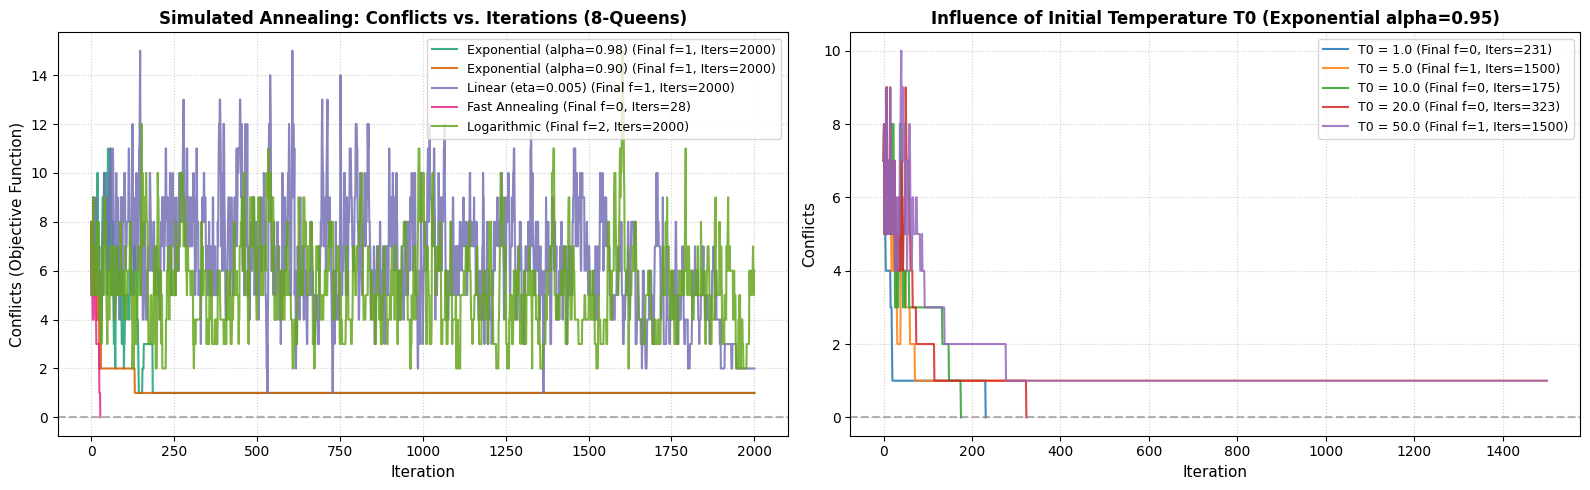


Discussion of Experimental Findings on Simulated Annealing:
1. Mechanism of Overcoming Local Optima:
   - In early iterations when T is high, the algorithm frequently accepts non-improving moves (delta >= 0),
     producing characteristic oscillations in the objective curve. This exploration prevents premature
     convergence into sub-optimal local basins.
   - As T decreases geometrically (exponential schedule), acceptance of uphill moves drops sharply,
     and the search transitions smoothly from global exploration to local exploitation.

2. Influence of Initial Temperature (T0):
   - If T0 is too low (e.g. T0 <= 1.0): The acceptance probability exp(-delta / T) is virtually zero even at
     t=1, turning SA into standard First-Choice Hill Climbing and causing it to freeze prematurely in local minima.
   - If T0 is too high (e.g. T0 >= 50.0): The algorithm behaves like an aimless random walk for hundreds of iterations,
     wasting computational budget before any meaningful gradien

In [9]:
import math

# ==============================================================================
# 1. COOLING SCHEDULE DEFINITIONS
# ==============================================================================
def temperature_exponential(time, initial_temperature=10.0, alpha=0.95):
    """Exponential cooling: T(t) = T0 * alpha^t."""
    return initial_temperature * (alpha ** time)

def temperature_linear(time, initial_temperature=10.0, eta=0.005):
    """Linear cooling: T(t) = max(0, T0 - eta * t)."""
    return max(0.0, initial_temperature - eta * time)

def temperature_fast(time, initial_temperature=10.0):
    """Fast annealing: T(t) = T0 / (1 + t)."""
    return initial_temperature / (1.0 + time)

def temperature_logarithmic(time, initial_temperature=10.0):
    """Logarithmic cooling: T(t) = T0 / ln(1 + t)."""
    return initial_temperature / np.log1p(time)


# ==============================================================================
# 2. SIMULATED ANNEALING IMPLEMENTATION
# ==============================================================================
def simulated_annealing(
    board,
    schedule=temperature_exponential,
    initial_temperature=10.0,
    max_iterations=5000,
    schedule_params=None,
    seed=None
):
    """Simulated Annealing search for the n-Queens problem.
    
    Standard API Output:
        solution: best board state found
        objective: lowest number of conflicts achieved
        history: sequence of objective values at each iteration
        iterations: total number of candidate moves evaluated
        evaluations: total conflict function evaluations
        stopped_reason: 'solution found' or 'iteration limit'
    """
    state = _validate_board(board)
    n = len(state)
    rng = np.random.default_rng(seed)

    current_objective = conflicts(state)
    best_state = state.copy()
    best_objective = current_objective

    history = [int(current_objective)]
    evaluations = 1
    iterations = 0
    params = schedule_params or {}

    for t in range(1, max_iterations + 1):
        if current_objective == 0:
            break

        iterations += 1
        T = schedule(t, initial_temperature=initial_temperature, **params)

        # Generate exactly one random local neighbour: random column, new row != old_row
        col = int(rng.integers(n))
        old_row = state[col]
        new_row = int(rng.integers(n - 1))
        if new_row >= old_row:
            new_row += 1

        candidate = state.copy()
        candidate[col] = new_row
        candidate_obj = conflicts(candidate)
        evaluations += 1

        delta = candidate_obj - current_objective

        if delta < 0:
            # Better move: unconditionally accept
            state, current_objective = candidate, candidate_obj
            if current_objective < best_objective:
                best_objective, best_state = current_objective, state.copy()
        else:
            # Worse or equal move: accept with Metropolis probability exp(-delta / T)
            if T > 1e-12:
                prob = math.exp(-delta / T)
                if rng.random() < prob:
                    state, current_objective = candidate, candidate_obj

        history.append(int(current_objective))

    reason = "solution found" if best_objective == 0 else "iteration limit"
    return _search_result(best_state, best_objective, history, iterations, evaluations, reason)


# ==============================================================================
# 3. EXPERIMENTAL VISUALIZATION: Search Process & Annealing Schedules
# ==============================================================================
test_board_8 = np.random.default_rng(2027).integers(0, 8, size=8)
print(f"Initial 8-Queens Board: {test_board_8} | Initial conflicts: {conflicts(test_board_8)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Comparison of cooling schedules on the exact same 8-queens starting board
schedules_to_test = [
    ("Exponential (alpha=0.98)", temperature_exponential, {"alpha": 0.98}, "#1b9e77"),
    ("Exponential (alpha=0.90)", temperature_exponential, {"alpha": 0.90}, "#d95f02"),
    ("Linear (eta=0.005)", temperature_linear, {"eta": 0.005}, "#7570b3"),
    ("Fast Annealing", temperature_fast, {}, "#e7298a"),
    ("Logarithmic", temperature_logarithmic, {}, "#66a61e"),
]

for name, sched, s_params, col in schedules_to_test:
    res = simulated_annealing(test_board_8, schedule=sched, initial_temperature=10.0,
                              max_iterations=2000, schedule_params=s_params, seed=42)
    ax1.plot(res['history'], label=f"{name} (Final f={res['objective']}, Iters={res['iterations']})",
             color=col, alpha=0.85, linewidth=1.5)

ax1.set_title("Simulated Annealing: Conflicts vs. Iterations (8-Queens)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Iteration", fontsize=11)
ax1.set_ylabel("Conflicts (Objective Function)", fontsize=11)
ax1.axhline(0, color='gray', linestyle='--', alpha=0.6)
ax1.legend(fontsize=9, loc='upper right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot 2: Influence of Initial Temperature T0 on convergence
t0_values = [1.0, 5.0, 10.0, 20.0, 50.0]
for t0 in t0_values:
    res_t0 = simulated_annealing(test_board_8, schedule=temperature_exponential,
                                 initial_temperature=t0, schedule_params={"alpha": 0.95},
                                 max_iterations=1500, seed=42)
    ax2.plot(res_t0['history'], label=f"T0 = {t0:.1f} (Final f={res_t0['objective']}, Iters={res_t0['iterations']})",
             alpha=0.85, linewidth=1.5)

ax2.set_title("Influence of Initial Temperature T0 (Exponential alpha=0.95)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Iteration", fontsize=11)
ax2.set_ylabel("Conflicts", fontsize=11)
ax2.axhline(0, color='gray', linestyle='--', alpha=0.6)
ax2.legend(fontsize=9, loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# ==============================================================================
# 4. DISCUSSION OF FINDINGS
# ==============================================================================
print("""
Discussion of Experimental Findings on Simulated Annealing:
1. Mechanism of Overcoming Local Optima:
   - In early iterations when T is high, the algorithm frequently accepts non-improving moves (delta >= 0),
     producing characteristic oscillations in the objective curve. This exploration prevents premature
     convergence into sub-optimal local basins.
   - As T decreases geometrically (exponential schedule), acceptance of uphill moves drops sharply,
     and the search transitions smoothly from global exploration to local exploitation.

2. Influence of Initial Temperature (T0):
   - If T0 is too low (e.g. T0 <= 1.0): The acceptance probability exp(-delta / T) is virtually zero even at
     t=1, turning SA into standard First-Choice Hill Climbing and causing it to freeze prematurely in local minima.
   - If T0 is too high (e.g. T0 >= 50.0): The algorithm behaves like an aimless random walk for hundreds of iterations,
     wasting computational budget before any meaningful gradient descent begins.
   - Optimal range: T0 in [10.0, 20.0] provides balanced initial exploration for n-Queens where typical energy barriers
     delta are between 1 and 4 conflicts.

3. Influence of Decay Rate (alpha / eta):
   - In Exponential cooling, alpha in [0.95, 0.98] provides an ideal cooling rate: steady progress without quenching.
   - If alpha is too low (e.g. alpha <= 0.85): Premature freezing (quenching) occurs before the global minimum is reached.
   - If alpha is too high (e.g. alpha >= 0.99): The temperature remains elevated for too long, delaying convergence.
   - Fast annealing (T0 / (1 + t)) drops temperature rapidly at first but maintains a long tail, occasionally achieving very fast convergence.
   - Logarithmic cooling decays far too slowly for practical budgets, spending too many iterations fluctuating at high conflict counts.
""")


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison

Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm               | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution |
| ----------------------- | ---------- | ------------- | ------------------------ | ------------------------------------ |
| Steepest asc. HC        | 4          |               |                          |                                      |
| Ineff. Stochastic HC    | 4          |               |                          |                                      |
| Efficient Stochastic HC | 4          |               |                          |                                      |
| Simulated Annealing     | 4          |               |                          |                                      |
| Steepest asc. HC        | 8          |               |                          |                                      |
| Ineff. Stochastic HC    | 8          |               |                          |                                      |
| Efficient Stochastic HC | 8          |               |                          |                                      |
| Simulated Annealing     | 8          |               |                          |                                      |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:


In [ ]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.


In [ ]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.


In [ ]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

- **Graduate students** need to complete this task [10 points]
- **Undergraduate students** can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

- Single-step move: Move one queen only one square up or down at a time
- Column swap: Exchange the positions of queens in two randomly selected columns
- Dual-queen move: Select two queens and move both simultaneously
- Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your **Efficient Stochastic Hill Climbing** implementation with each move operator 100 times.

For each operator, create a visualization showing:

- Average solution quality over iterations
- Distribution of final solution qualities
- Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?


In [9]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem


In [10]:
# Code and description go here